# Multi-Brand Marketing Campaign Performance Analysis & Prediction
**Nykaa · Purplle · Tira: cleaning → feature engineering → EDA → regression & classification**

This notebook walks through the pipeline using the functions in `src/`. `run_pipeline.py` runs the same steps from the command line, and `app.py` serves the saved models.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings('ignore')

import pandas as pd, numpy as np
from IPython.display import Image, display

from src import config, cleaning, features, eda, train
from src.predict import predict_campaign
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)

## 1. Data collection: CSV → DataFrame
Three brand files are loaded and stacked, with a `Brand` column added.

In [2]:
raw = cleaning.load_raw().drop(columns=['_row', '_prefix'])
print(raw.shape)
raw.groupby('Brand').size()

(166665, 17)


Brand
Nykaa      55555
Purplle    55555
Tira       55555
dtype: int64

In [3]:
raw.head()

,Brand,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,Nykaa,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",57804.0,6156.0,3616.0,2355.0,1867515.0,NaN,6.14,Hindi,20.98,College Students,29-04-2025
1,Nykaa,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83,3.26,Hindi,7.24,College Students,06-04-2025
2,Nykaa,NY-CMP-1002,Influencer,Youth,23.0,"WhatsApp, Google, YouTube",15536.0,2182.0,952.0,755.0,197055.0,90.60,NaN,English,25.03,College Students,14-01-2025
3,Nykaa,NY-CMP-1003,Email,Working Women,18.0,"YouTube, Facebook, Instagram",88114.0,8413.0,2231.0,947.0,376906.0,249.07,0.60,Hindi,13.15,NaN,04-06-2025
4,Nykaa,NY-CMP-1004,Paid Ads,College Students,10.0,"Facebook, Instagram",96871.0,3743.0,2060.0,1258.0,518296.0,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024


In [4]:
raw.dtypes.to_frame('dtype').T

,Brand,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
dtype,str,str,str,str,float64,str,float64,float64,float64,float64,float64,float64,float64,str,float64,str,str


### Missing values
Every column (even `Campaign_ID` for Purplle and Tira) is about 5% empty, and **more than half of all rows have at least one gap**, so dropping incomplete rows is not an option.

In [5]:
miss = (raw.drop(columns='Brand').isna().groupby(raw['Brand']).mean() * 100).round(2).T
miss

Brand,Nykaa,Purplle,Tira
Campaign_ID,0.00,4.83,4.92
Campaign_Type,5.15,5.02,4.88
Target_Audience,4.97,4.94,4.80
Duration,5.20,4.98,4.80
Channel_Used,5.05,4.94,4.92
Impressions,5.00,4.90,4.90
Clicks,5.01,4.88,4.91
Leads,5.00,4.78,4.78
Conversions,4.80,4.81,4.79
Revenue,5.06,4.97,4.91


In [6]:
print('Rows with any missing value: %.1f%%' % (raw.isna().any(axis=1).mean() * 100))
print('Exact duplicate rows:', raw.duplicated().sum())

Rows with any missing value: 54.7%
Exact duplicate rows: 0


### Validating ROI
ROI turns out to follow exactly `ROI = (Revenue − Spend) / Spend`, where `Spend = Acquisition_Cost × Conversions`.

In [7]:
spend = raw.Acquisition_Cost * raw.Conversions
calc = (raw.Revenue - spend) / spend
diff = (calc - raw.ROI).abs().dropna()
print(f'rows checked: {len(diff):,}  max |diff|: {diff.max():.4f}  (rounding only)')
print('Order value per conversion (Revenue / Conversions):')
(raw.Revenue / raw.Conversions).describe().round(1)

rows checked: 136,312  max |diff|: 0.0279  (rounding only)
Order value per conversion (Revenue / Conversions):


count    150748.0
mean        499.6
std         173.6
min         200.0
25%         349.0
50%         499.0
75%         650.0
max         800.0
dtype: float64

Because this identity holds, a missing ROI, Revenue, Acquisition_Cost or Conversions value can be **recovered exactly** from the other three, instead of being guessed.

## 2. Cleaning & preprocessing

In [8]:
clean, rep = cleaning.clean(cleaning.load_raw())
clean.to_csv(config.CLEAN_CSV, index=False)
with open(config.CLEANING_REPORT, 'w') as fh: json.dump(rep, fh, indent=2, default=str)
print(json.dumps({k: rep[k] for k in ['campaign_id_rebuilt', 'duplicate_rows', 'roi_corrected', 'recovered_by_roi_identity', 'rows_dropped_target_unrecoverable', 'imputation', 'rows_final']}, indent=1))

{
  "rows_raw": 166665,
  "roi_corrected": 0,
  "recovered_by_roi_identity": {
    "ROI": 7064,
    "Revenue": 7137,
    "Acquisition_Cost": 6991,
    "Conversions": 6846
  },
  "rows_dropped_target_unrecoverable": 1953,
  "rows_final": 164712
}


{
 "campaign_id_rebuilt": 5417,
 "duplicate_rows": 0,
 "roi_corrected": 0,
 "recovered_by_roi_identity": {
  "ROI": 7064,
  "Revenue": 7137,
  "Acquisition_Cost": 6991,
  "Conversions": 6846
 },
 "rows_dropped_target_unrecoverable": 1953,
 "imputation": {
  "conversions_and_cost_from_spend": 362,
  "funnel_ratio": {
   "Impressions": 8123,
   "Clicks": 8124,
   "Leads": 7999
  },
  "engagement_from_ctr": 7978,
  "brand_median": {
   "Duration": 8236
  },
  "unknown_category": {
   "Campaign_Type": 8257,
   "Target_Audience": 8081,
   "Channel_Used": 8184,
   "Language": 8205,
   "Customer_Segment": 8088
  },
  "date_missing_left_as_NaT": 7989
 },
 "rows_final": 164712
}


In [9]:
print('Missing after cleaning:', clean.isna().sum()[clean.isna().sum() > 0].to_dict())
clean.head()

Missing after cleaning: {'Date': 7989}


,Brand,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,Nykaa,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,111.06,6.1403,Hindi,20.98,College Students,2025-04-29
1,Nykaa,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,180.83,3.2637,Hindi,7.24,College Students,2025-04-06
2,Nykaa,NY-CMP-1002,Influencer,Youth,23,"Google, WhatsApp, YouTube",15536,2182,952,755,197055,90.60,1.8808,English,25.03,College Students,2025-01-14
3,Nykaa,NY-CMP-1003,Email,Working Women,18,"Facebook, Instagram, YouTube",88114,8413,2231,947,376906,249.07,0.5979,Hindi,13.15,Unknown,2025-06-04
4,Nykaa,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296,228.60,0.8023,Hindi,7.29,Tier 2 City Customers,2024-12-29


## 3. Feature engineering
* **Multi-label encoding** of `Channel_Used` (`'Google, YouTube'` → `Ch_Google=1, Ch_YouTube=1`)
* **Profit_Flag** = 1 if ROI > 0, else 0
* `Total_Spend`, `CTR`, `Lead_Rate`, `Conversion_Rate`, `Month`, `Weekday`

In [10]:
feat = features.add_features(clean)
feat.to_csv(config.FEATURES_CSV, index=False)
feat[['Channel_Used'] + config.CHANNEL_COLS + ['Num_Channels']].drop_duplicates('Channel_Used').head(8)

,Channel_Used,Ch_Email,Ch_Facebook,Ch_Google,Ch_Instagram,Ch_WhatsApp,Ch_YouTube,Num_Channels
0,"WhatsApp, YouTube",0,0,0,0,1,1,2
1,YouTube,0,0,0,0,0,1,1
2,"Google, WhatsApp, YouTube",0,0,1,0,1,1,3
3,"Facebook, Instagram, YouTube",0,1,0,1,0,1,3
4,"Facebook, Instagram",0,1,0,1,0,0,2
5,"Email, Instagram",1,0,0,1,0,0,2
7,Unknown,0,0,0,0,0,0,0
8,"Email, Facebook, WhatsApp",1,1,0,0,1,0,3


In [11]:
feat[['ROI', 'Profit_Flag', 'Profit_Label', 'Total_Spend', 'CTR', 'Lead_Rate', 'Conversion_Rate']].head()

,ROI,Profit_Flag,Profit_Label,Total_Spend,CTR,Lead_Rate,Conversion_Rate
0,6.1403,1,Profit,261546.30,0.106498,0.587394,0.651272
1,3.2637,1,Profit,245386.31,0.036176,0.593496,0.688483
2,1.8808,1,Profit,68403.00,0.140448,0.436297,0.793067
3,0.5979,1,Profit,235869.29,0.095479,0.265185,0.424473
4,0.8023,1,Profit,287578.80,0.038639,0.550361,0.610680


In [12]:
feat.Profit_Label.value_counts(normalize=True).round(3)

Profit_Label
Profit    0.761
Loss      0.239
Name: proportion, dtype: float64

## 4. Exploratory data analysis

In [13]:
s = eda.run_eda(feat)
pd.DataFrame(s['brand']).T

,campaigns,revenue,spend,avg_roi,median_roi,profit_rate,avg_ctr,avg_engagement,portfolio_roi
Nykaa,54878.0,2.832575e+10,9.579612e+09,2.7167,1.2420,0.7608,0.0851,13.7788,1.9569
Purplle,54908.0,2.818720e+10,9.607415e+09,2.6786,1.2220,0.7589,0.0851,13.7544,1.9339
Tira,54926.0,2.813219e+10,9.601764e+09,2.6778,1.2366,0.7643,0.0851,13.7598,1.9299


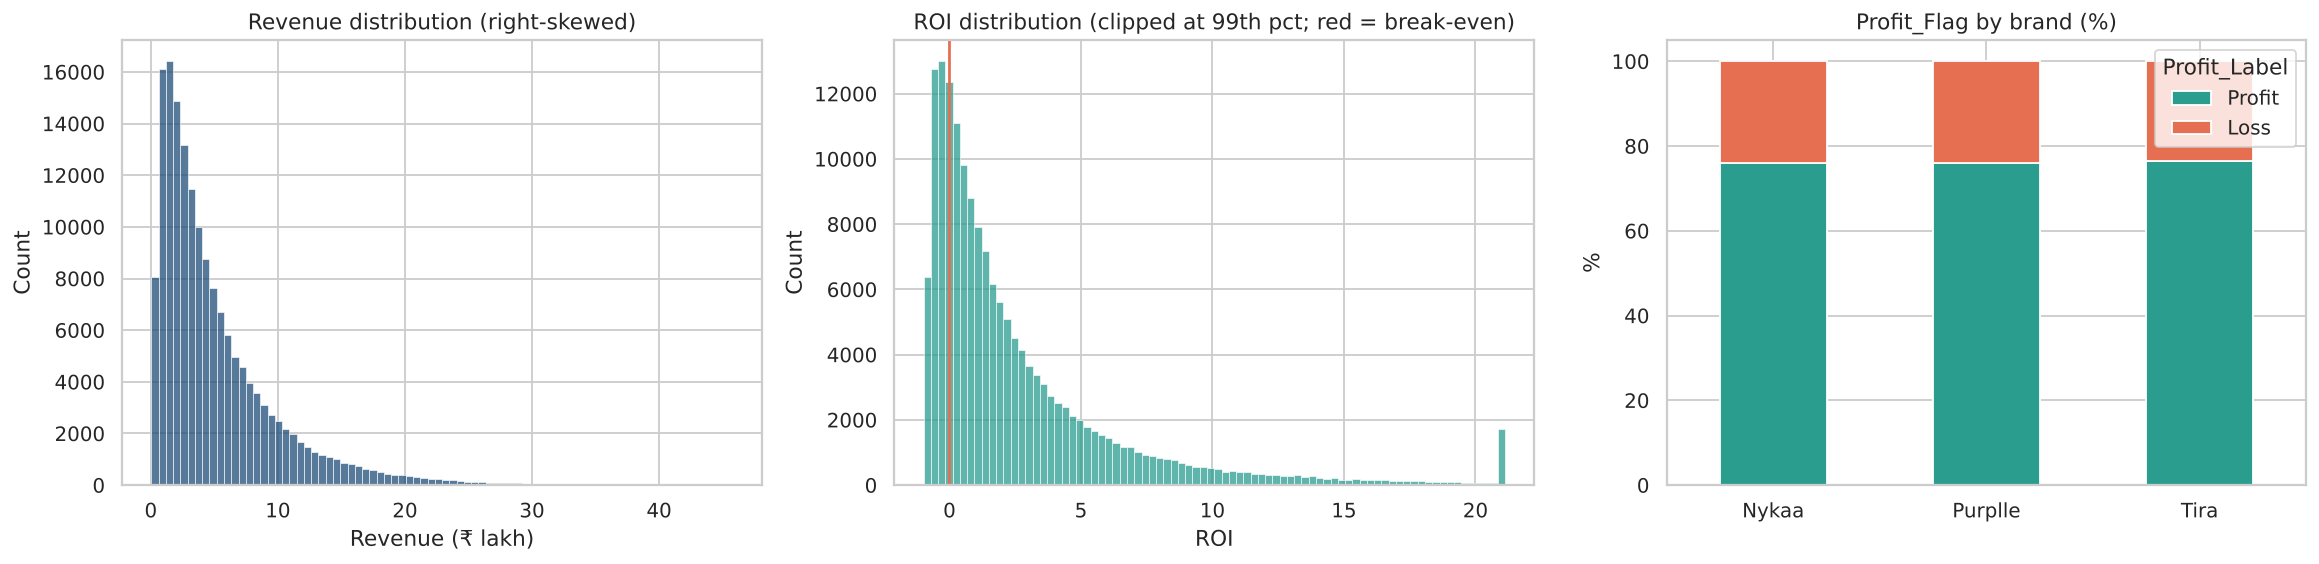

In [14]:
display(Image(config.FIGURES_DIR / '00_target_distributions.png'))

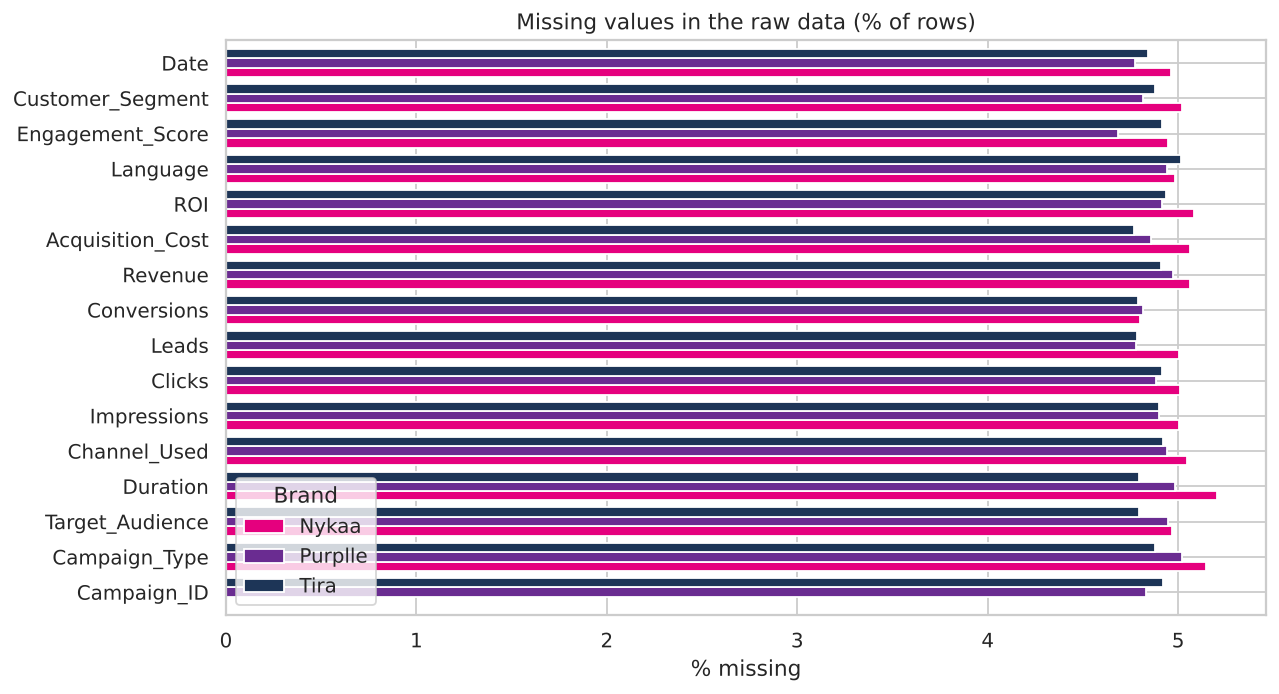

In [15]:
display(Image(config.FIGURES_DIR / '01_missing_values.png'))

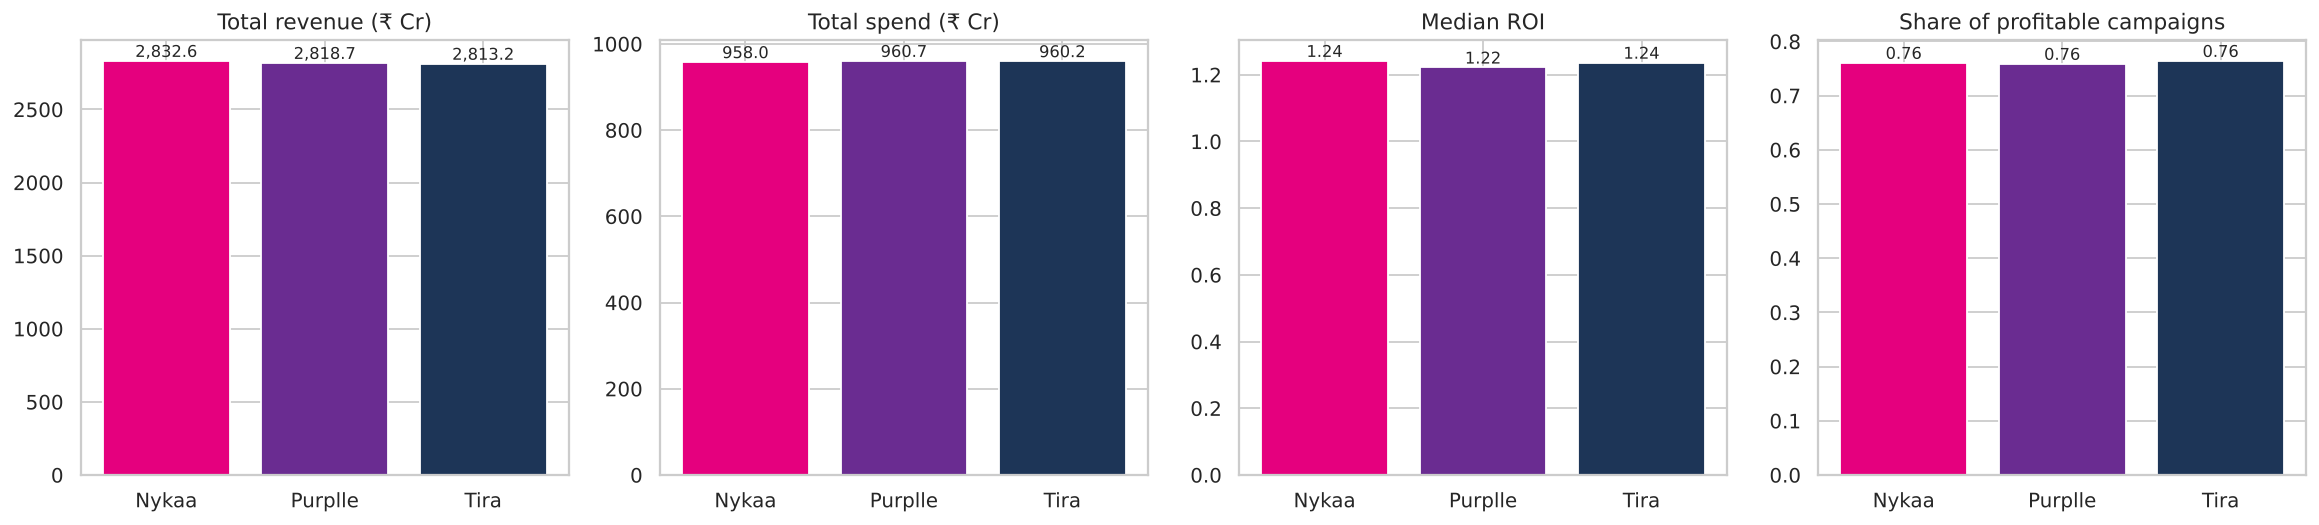

In [16]:
display(Image(config.FIGURES_DIR / '02_brand_performance.png'))

The three brands are almost identical on every metric, at around 76% profitable campaigns and a portfolio ROI of about 1.94.

In [17]:
pd.DataFrame(s['campaign_type']).T

,campaigns,median_roi,profit_rate,avg_revenue,avg_conversions
Email,31430.0,1.2205,0.7582,513604.1976,1028.0025
Influencer,31468.0,1.2086,0.7590,509936.0382,1025.0504
Paid Ads,31258.0,1.2650,0.7647,518905.1302,1033.8306
SEO,31175.0,1.2229,0.7586,510615.2931,1021.7065
Social Media,31124.0,1.2423,0.7675,515893.7998,1035.3383


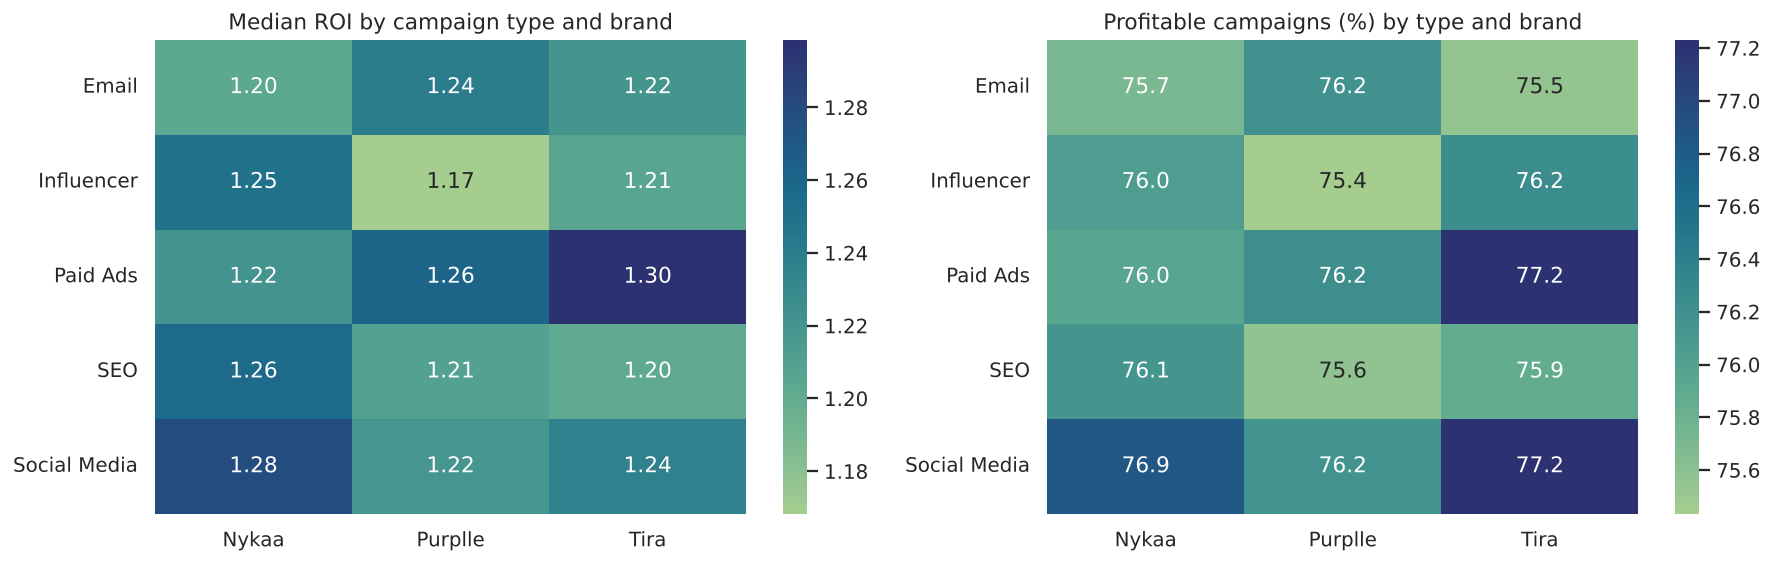

In [18]:
display(Image(config.FIGURES_DIR / '03_campaign_type_brand.png'))

### Top and bottom campaigns

In [19]:
pd.DataFrame(s['top10_roi'])

,Campaign_ID,Brand,Campaign_Type,Channel_Used,Revenue,Total_Spend,ROI
0,TI-CMP-46406,Tira,Social Media,"Google, Instagram",4041864,50323.36,79.32
1,NY-CMP-13007,Nykaa,Paid Ads,"Email, Facebook, YouTube",4579910,60708.88,74.44
2,TI-CMP-18349,Tira,Paid Ads,"Facebook, Google",4045290,55294.56,72.16
3,PU-CMP-41973,Purplle,Paid Ads,Instagram,3467292,51088.86,66.87
4,NY-CMP-22689,Nykaa,Influencer,"Instagram, YouTube",3821485,56764.20,66.32
5,NY-CMP-49715,Nykaa,Paid Ads,WhatsApp,3717208,56341.12,64.98
6,TI-CMP-9758,Tira,Email,"Instagram, WhatsApp",3392874,51551.70,64.82
7,NY-CMP-26356,Nykaa,Paid Ads,Facebook,3363384,51641.76,64.13
8,PU-CMP-30181,Purplle,SEO,WhatsApp,3278224,50460.88,63.97
9,PU-CMP-8989,Purplle,SEO,"Email, YouTube",3668850,58683.00,61.52


In [20]:
pd.DataFrame(s['bottom10_roi'])

,Campaign_ID,Brand,Campaign_Type,Channel_Used,Revenue,Total_Spend,ROI
0,TI-CMP-29039,Tira,Email,Email,3895,285722.00,-0.99
1,TI-CMP-20738,Tira,Influencer,"Email, Instagram, WhatsApp",6072,279918.10,-0.98
2,PU-CMP-24764,Purplle,Influencer,Unknown,7350,274769.95,-0.97
3,TI-CMP-56201,Tira,Email,Unknown,6987,251640.97,-0.97
4,TI-CMP-1359,Tira,Influencer,"Facebook, Instagram, WhatsApp",9180,299162.88,-0.97
5,PU-CMP-32028,Purplle,Email,Email,9072,271795.86,-0.97
6,NY-CMP-24406,Nykaa,Paid Ads,"Facebook, YouTube",6183,183750.12,-0.97
7,TI-CMP-16012,Tira,Paid Ads,Google,9625,286408.15,-0.97
8,TI-CMP-8939,Tira,Social Media,"Email, Instagram, WhatsApp",8695,248557.86,-0.96
9,PU-CMP-48283,Purplle,Social Media,"Facebook, WhatsApp",10422,295935.93,-0.96


In [21]:
pd.DataFrame(s['top_vs_bottom_decile_medians'])

,Top 10% ROI,Bottom 10% ROI
Acquisition_Cost,47.3450,1207.5200
CTR,0.1172,0.0439
Conversion_Rate,0.6274,0.4701
Engagement_Score,20.0900,6.4700
Conversions,2185.0000,173.0000
Num_Channels,2.0000,2.0000


### Spend, clicks, revenue and ROI

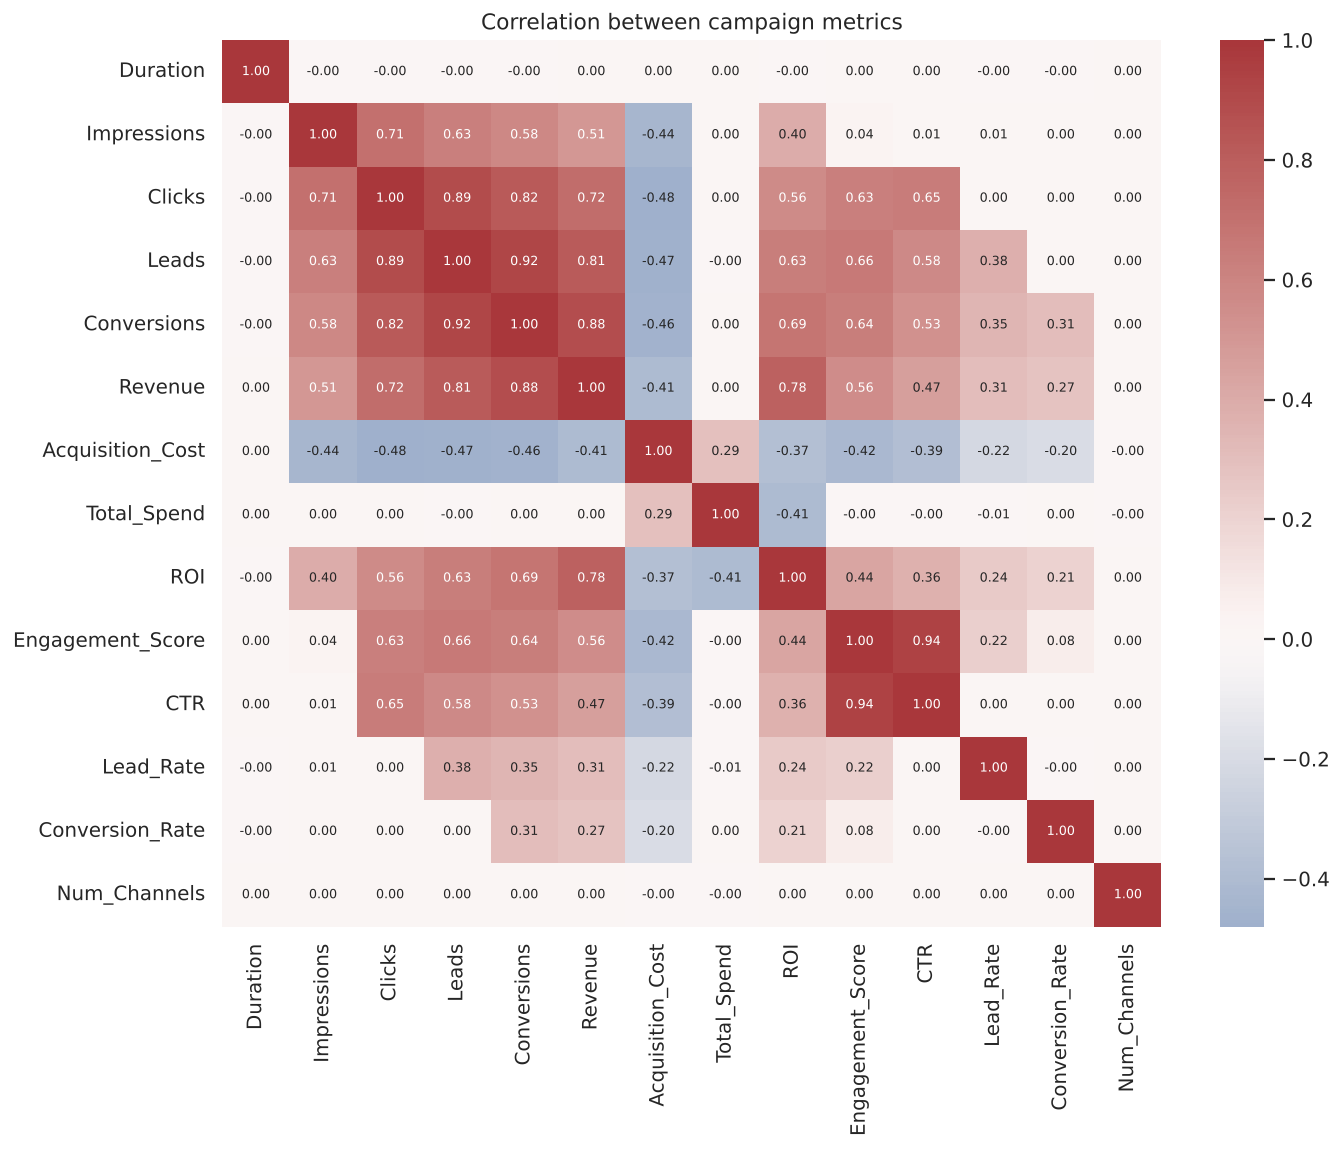

In [22]:
display(Image(config.FIGURES_DIR / '04_correlation.png'))

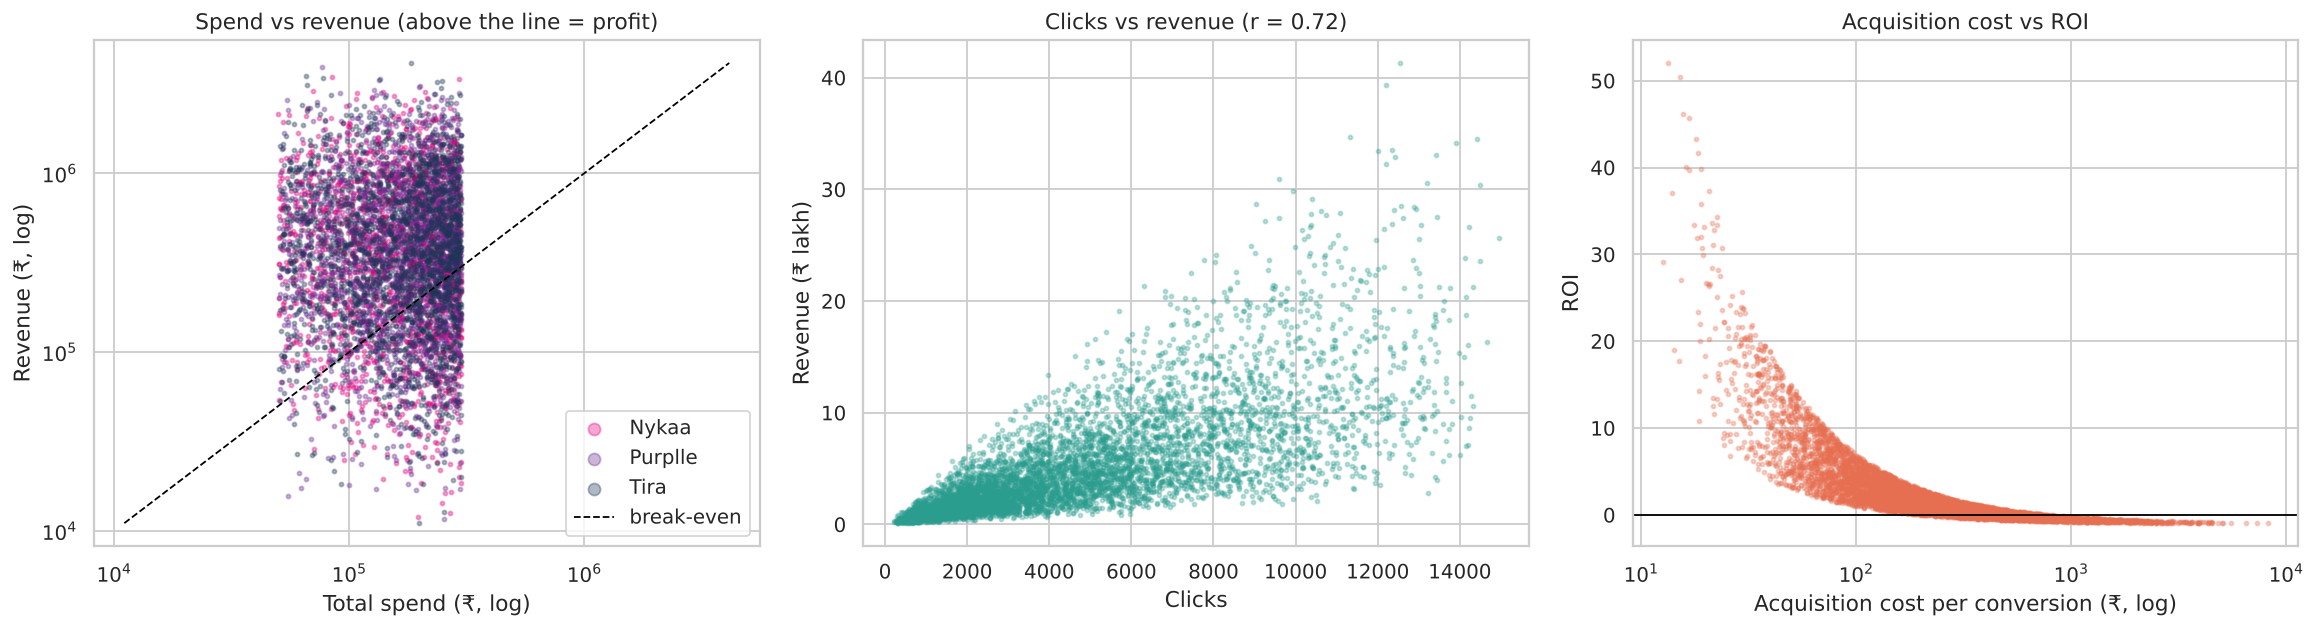

In [23]:
display(Image(config.FIGURES_DIR / '05_spend_clicks_revenue_roi.png'))

In [24]:
pd.DataFrame({'pearson': s['corr_with_roi'], 'spearman': s['spearman_with_roi']})

,pearson,spearman
Revenue,0.782,0.888
Conversions,0.686,0.812
Leads,0.633,0.772
Clicks,0.561,0.717
Engagement_Score,0.438,0.537
Impressions,0.396,0.524
CTR,0.364,0.468
Lead_Rate,0.244,0.280
Conversion_Rate,0.211,0.242
Num_Channels,0.003,0.003


### The key driver: acquisition cost per conversion
Order value per conversion is spread between ₹200 and ₹800, so a campaign is profitable exactly when the order value is higher than the acquisition cost.

In [25]:
pd.DataFrame(s['profit_by_cost_band']).T

,campaigns,profit_rate,median_roi
<100,37771.0,1.0000,6.7902
100-200,41999.0,1.0000,2.4146
200-300,25007.0,0.9211,1.0316
300-400,15419.0,0.7608,0.4500
400-500,10325.0,0.5941,0.1269
500-600,7263.0,0.4114,-0.0939
600-700,5411.0,0.2558,-0.2200
700-800,3952.0,0.0908,-0.3390
800-1k,5317.0,0.0002,-0.4472
1k-2k,9123.0,0.0000,-0.6329


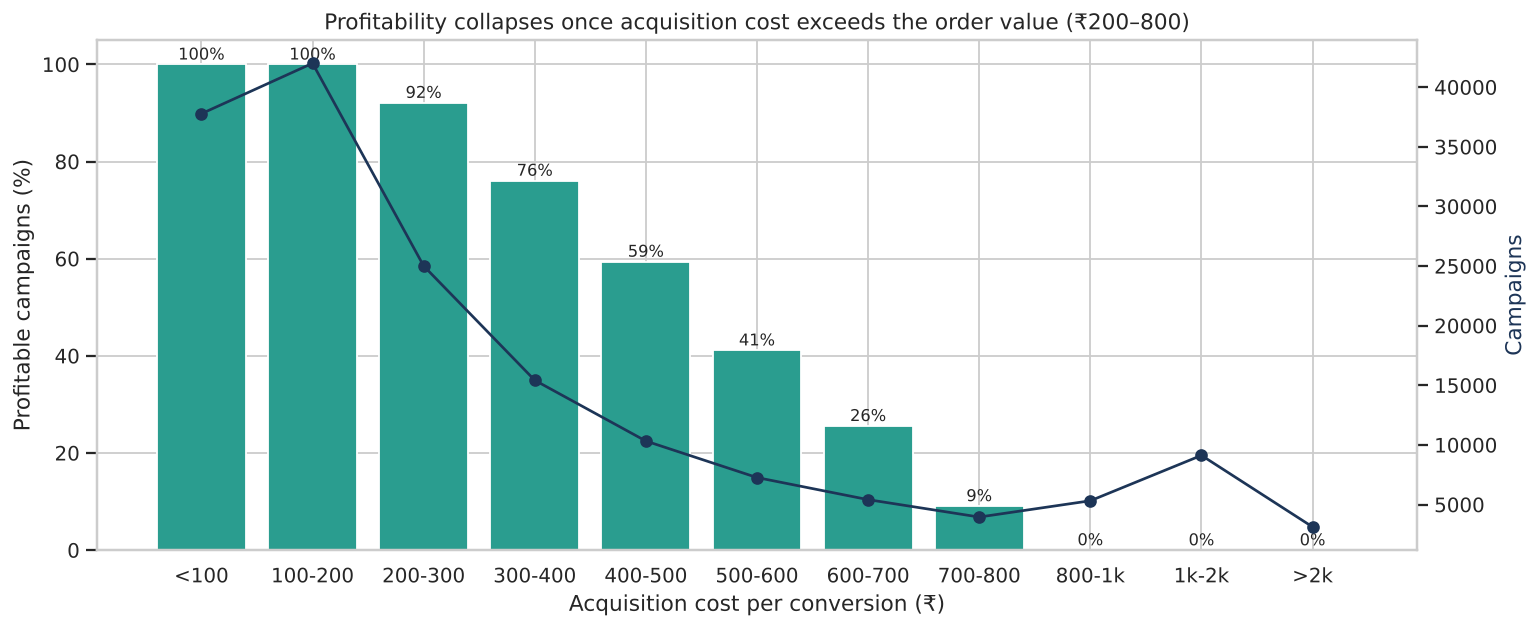

In [26]:
display(Image(config.FIGURES_DIR / '06_profit_by_acquisition_cost.png'))

### Channel effectiveness

In [27]:
pd.DataFrame(s['channel']).T

,campaigns,median_roi,mean_roi,profit_rate,avg_revenue,avg_ctr
Email,52265.0,1.2468,2.7312,0.7630,516975.9693,0.0855
Facebook,52223.0,1.2284,2.6826,0.7618,513711.6480,0.0850
Google,52214.0,1.2251,2.6886,0.7594,512103.9639,0.0848
Instagram,52228.0,1.2557,2.7248,0.7640,517270.4970,0.0854
WhatsApp,52105.0,1.2332,2.6817,0.7632,513485.9692,0.0853
YouTube,52153.0,1.2200,2.6693,0.7602,511810.4467,0.0850


In [28]:
pd.DataFrame(s['num_channels']).T

,campaigns,median_roi,profit_rate,avg_revenue
1,52119.0,1.2285,0.7615,514038.5540
2,52158.0,1.2362,0.7616,514542.2775
3,52251.0,1.2380,0.7623,514081.2702


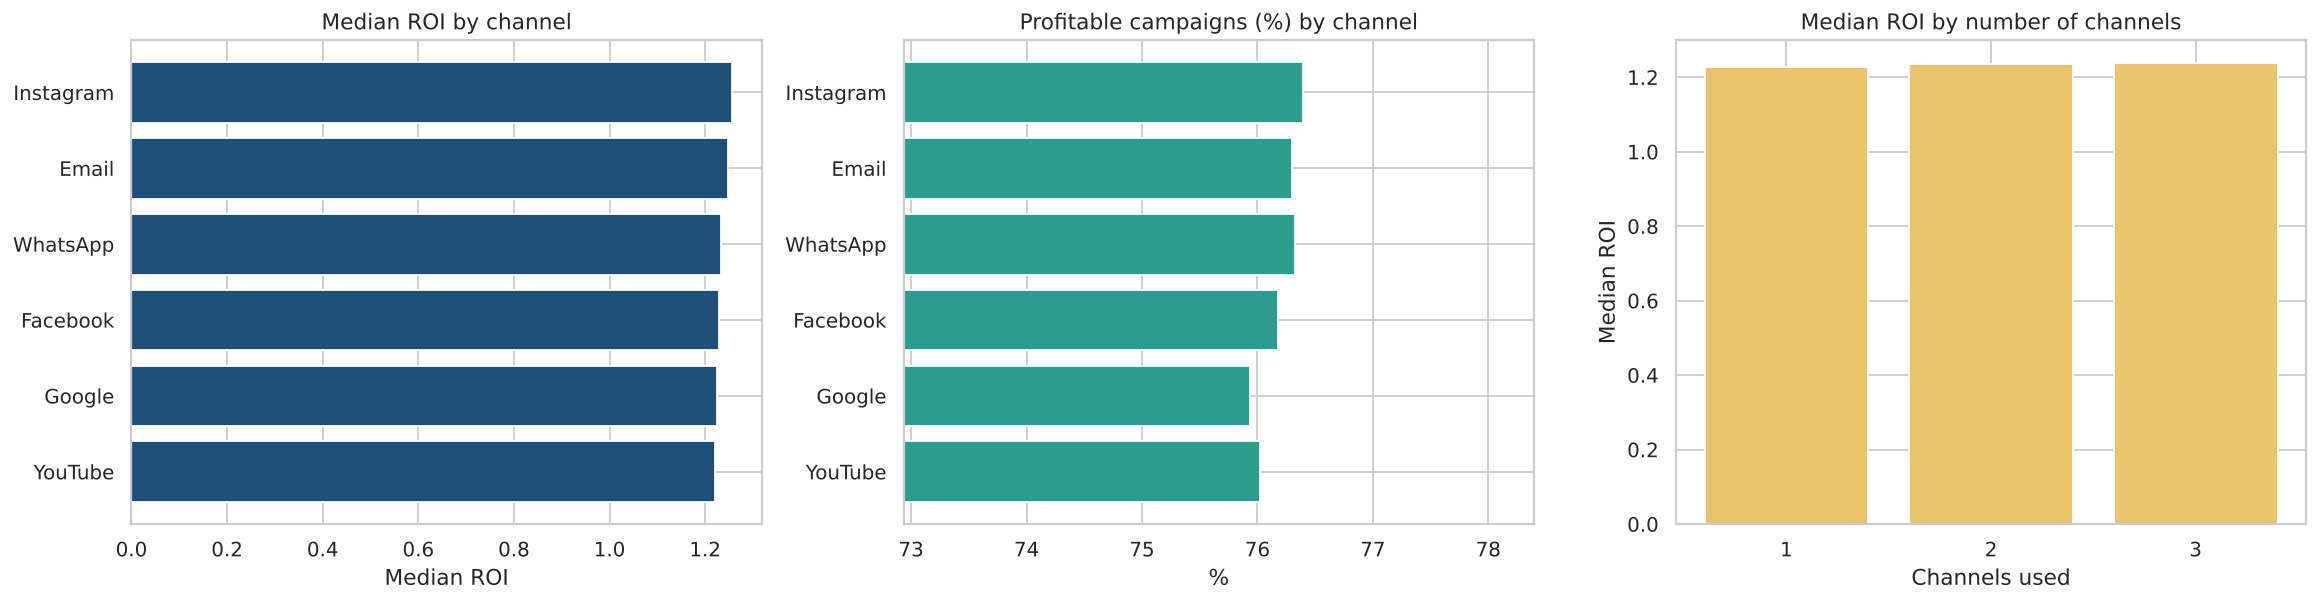

In [29]:
display(Image(config.FIGURES_DIR / '07_channel_effectiveness.png'))

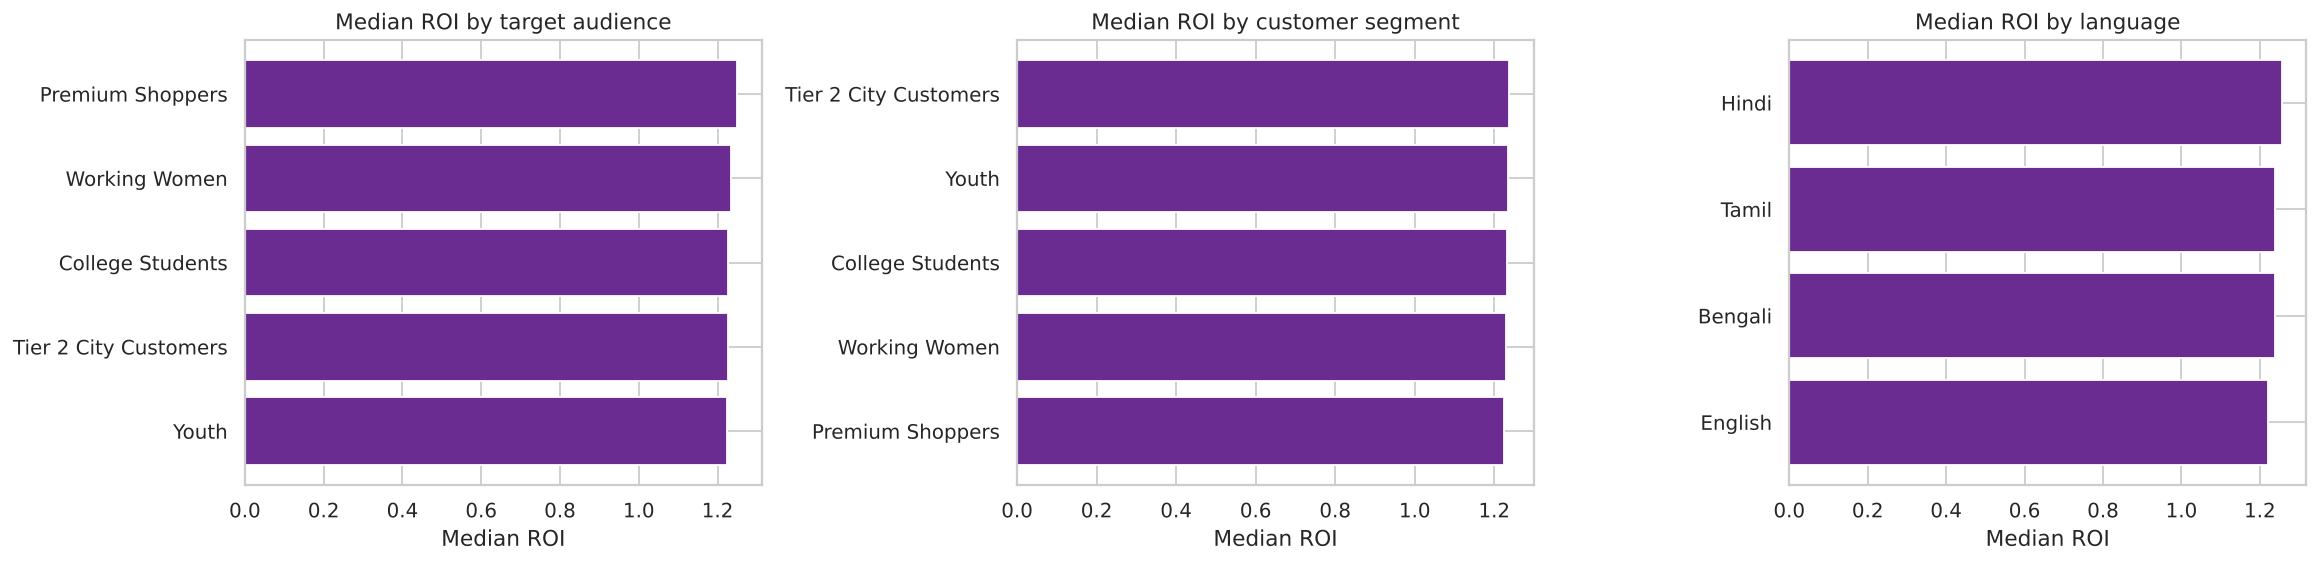

In [30]:
display(Image(config.FIGURES_DIR / '08_audience_segment_language.png'))

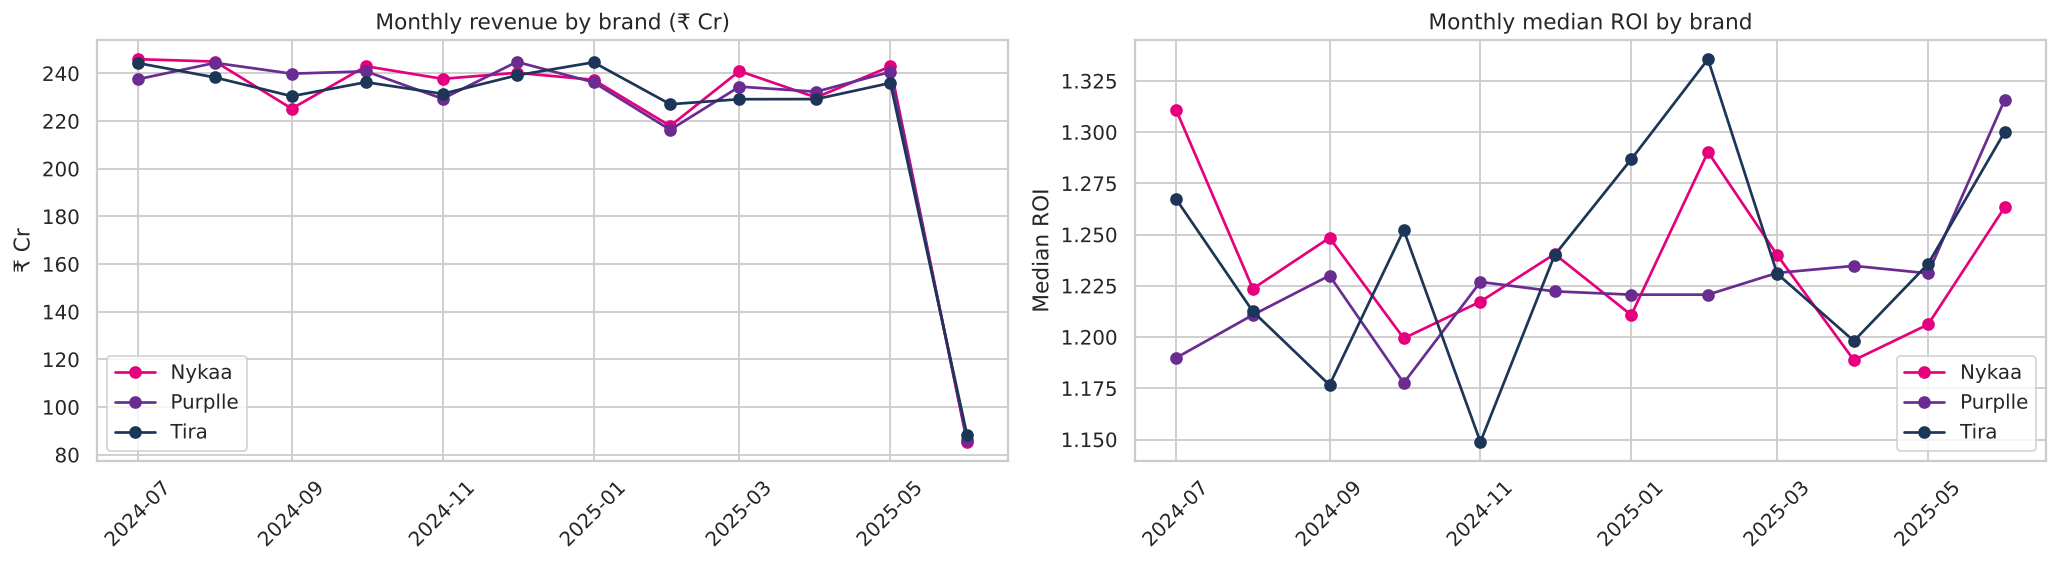

In [31]:
display(Image(config.FIGURES_DIR / '09_monthly_trend.png'))

## 5. Model building
* **Split:** stratified 80/20 train/test. 3-fold CV on the training data picks the algorithm, the best one is tuned with `RandomizedSearchCV`, and the test set is used once.
* **Pipeline:** median imputation → log1p for skewed money/count columns → scaling; one-hot encoding for categories; channel flags passed through. Revenue is modelled on a log scale.
* **Leakage rule:** ROI is never a classification input (asserted in code).
* **Two feature sets:** *spec* follows the brief (the revenue model may use ROI; the classifier excludes ROI but may use Revenue). *forecast* removes both ROI and Revenue. *(~6 minutes)*

In [32]:
res = train.run(feat)

Train 131,769 | Test 32,943 | Profit share 0.761

--- regression / spec  (14 numeric features incl. ROI)


  Linear Regression    CV r2=1.0000  (1.4s)


  Decision Tree        CV r2=0.9956  (3.9s)


  Random Forest        CV r2=0.9982  (69.4s)


  Gradient Boosting    CV r2=0.9961  (11.7s)


  BEST Linear Regression: R2=1.0000, RMSE=6.2467, MAE=4.6801, MSE=39.0218, MAPE_pct=0.0021


... (16 outputs left out)

  Random Forest        CV accuracy=0.9112  (14.8s)


  Gradient Boosting    CV accuracy=0.9115  (4.0s)


  tuned Gradient Boosting: {'model__max_leaf_nodes': 31, 'model__max_iter': 300, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1} (0.9109 -> 0.9114)


  BEST Gradient Boosting: Accuracy=0.9088, Precision=0.9231, Recall=0.9601, F1=0.9413, ROC_AUC=0.9645


In [33]:
comp = pd.read_csv(config.REPORTS_DIR / 'model_comparison.csv')
comp[comp.task == 'regression'][['variant', 'model', 'cv_r2', 'test_R2', 'test_RMSE', 'test_MAE', 'test_MSE', 'tuned']]

,variant,model,cv_r2,test_R2,test_RMSE,test_MAE,test_MSE,tuned
0,spec,Linear Regression,1.0000,1.0000,6.2467,4.6801,3.902180e+01,True
1,spec,Random Forest,0.9982,0.9988,16557.6923,3871.7526,2.741572e+08,False
2,spec,Gradient Boosting,0.9961,0.9967,27537.6161,10380.8938,7.583203e+08,False
3,spec,Decision Tree,0.9956,0.9958,31366.3490,11527.2375,9.838478e+08,False
4,forecast,Linear Regression,0.7650,0.7621,235264.6102,156438.7136,5.534944e+10,True
5,forecast,Gradient Boosting,0.7617,0.7597,236420.5518,156777.3257,5.589468e+10,False
6,forecast,Random Forest,0.7577,0.7545,238975.3731,157904.1955,5.710923e+10,False
7,forecast,Decision Tree,0.7077,0.7090,260180.0051,165956.6694,6.769364e+10,False


In [34]:
comp[comp.task == 'classification'][['variant', 'model', 'cv_accuracy', 'test_Accuracy', 'test_Precision', 'test_Recall', 'test_F1', 'test_ROC_AUC', 'tuned']]

,variant,model,cv_accuracy,test_Accuracy,test_Precision,test_Recall,test_F1,test_ROC_AUC,tuned
8,spec,Logistic Regression,0.9986,0.9986,0.9992,0.9990,0.9991,1.0000,True
9,spec,Gradient Boosting,0.9980,0.9980,0.9985,0.9988,0.9987,1.0000,False
10,spec,Decision Tree,0.9956,0.9961,0.9973,0.9977,0.9975,0.9968,False
11,spec,Random Forest,0.9802,0.9828,0.9857,0.9919,0.9888,0.9984,False
12,forecast,Gradient Boosting,0.9115,0.9088,0.9231,0.9601,0.9413,0.9645,True
13,forecast,Random Forest,0.9112,0.9083,0.9234,0.9592,0.9409,0.9634,False
14,forecast,Logistic Regression,0.9112,0.9086,0.9304,0.9510,0.9406,0.9650,False
15,forecast,Decision Tree,0.9021,0.9016,0.9211,0.9523,0.9365,0.9481,False


## 6. Model evaluation

In [35]:
pd.DataFrame({k: v['test_metrics'] for k, v in res.items()}).round(4)

,regression_spec,regression_forecast,classification_spec,classification_forecast
R2,1.0000,7.621000e-01,NaN,NaN
RMSE,6.2467,2.352646e+05,NaN,NaN
MAE,4.6801,1.564387e+05,NaN,NaN
MSE,39.0218,5.534944e+10,NaN,NaN
MAPE_pct,0.0021,3.534000e+01,NaN,NaN
Accuracy,NaN,NaN,0.9986,0.9088
Precision,NaN,NaN,0.9992,0.9231
Recall,NaN,NaN,0.9990,0.9601
F1,NaN,NaN,0.9991,0.9413
ROC_AUC,NaN,NaN,1.0000,0.9645


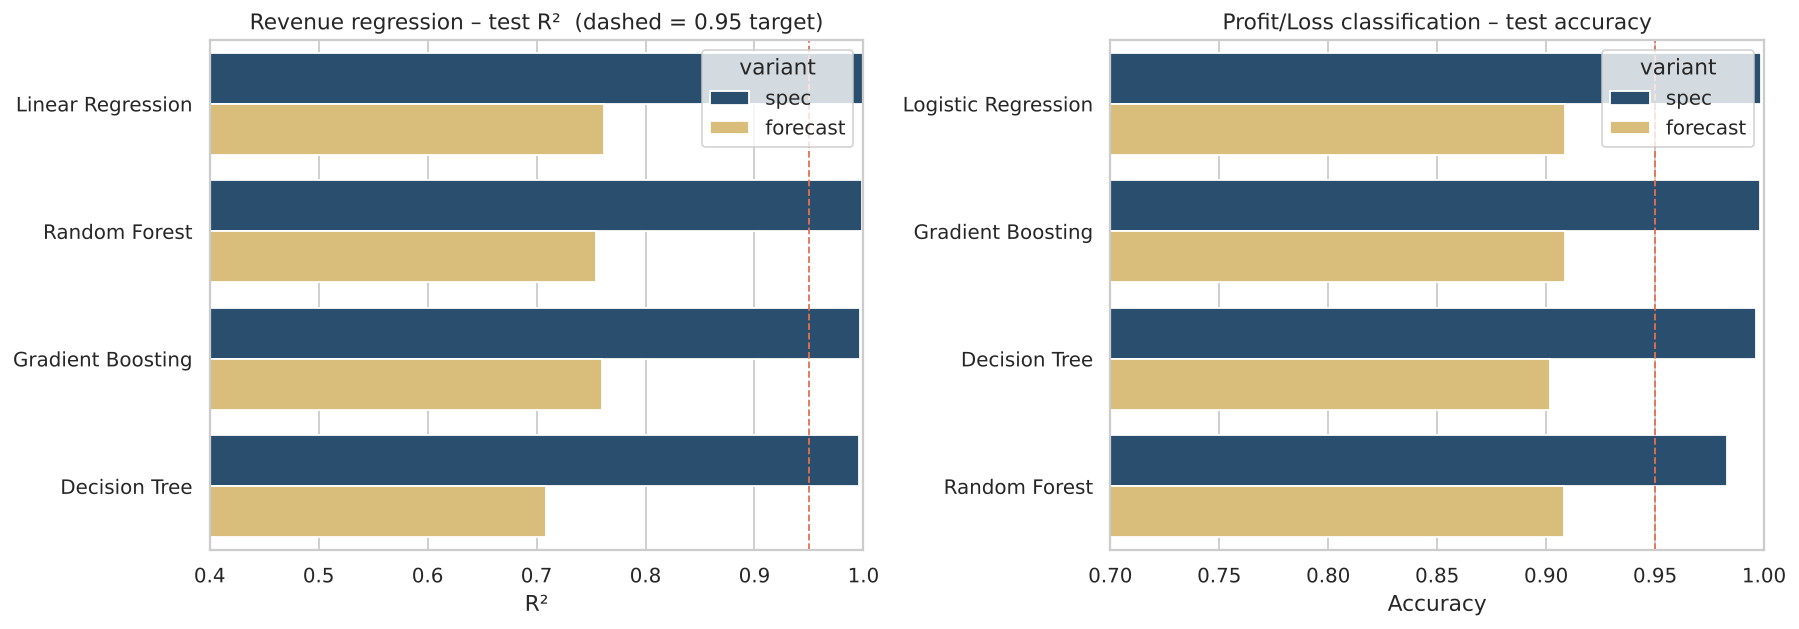

In [36]:
display(Image(config.FIGURES_DIR / '10_model_comparison.png'))

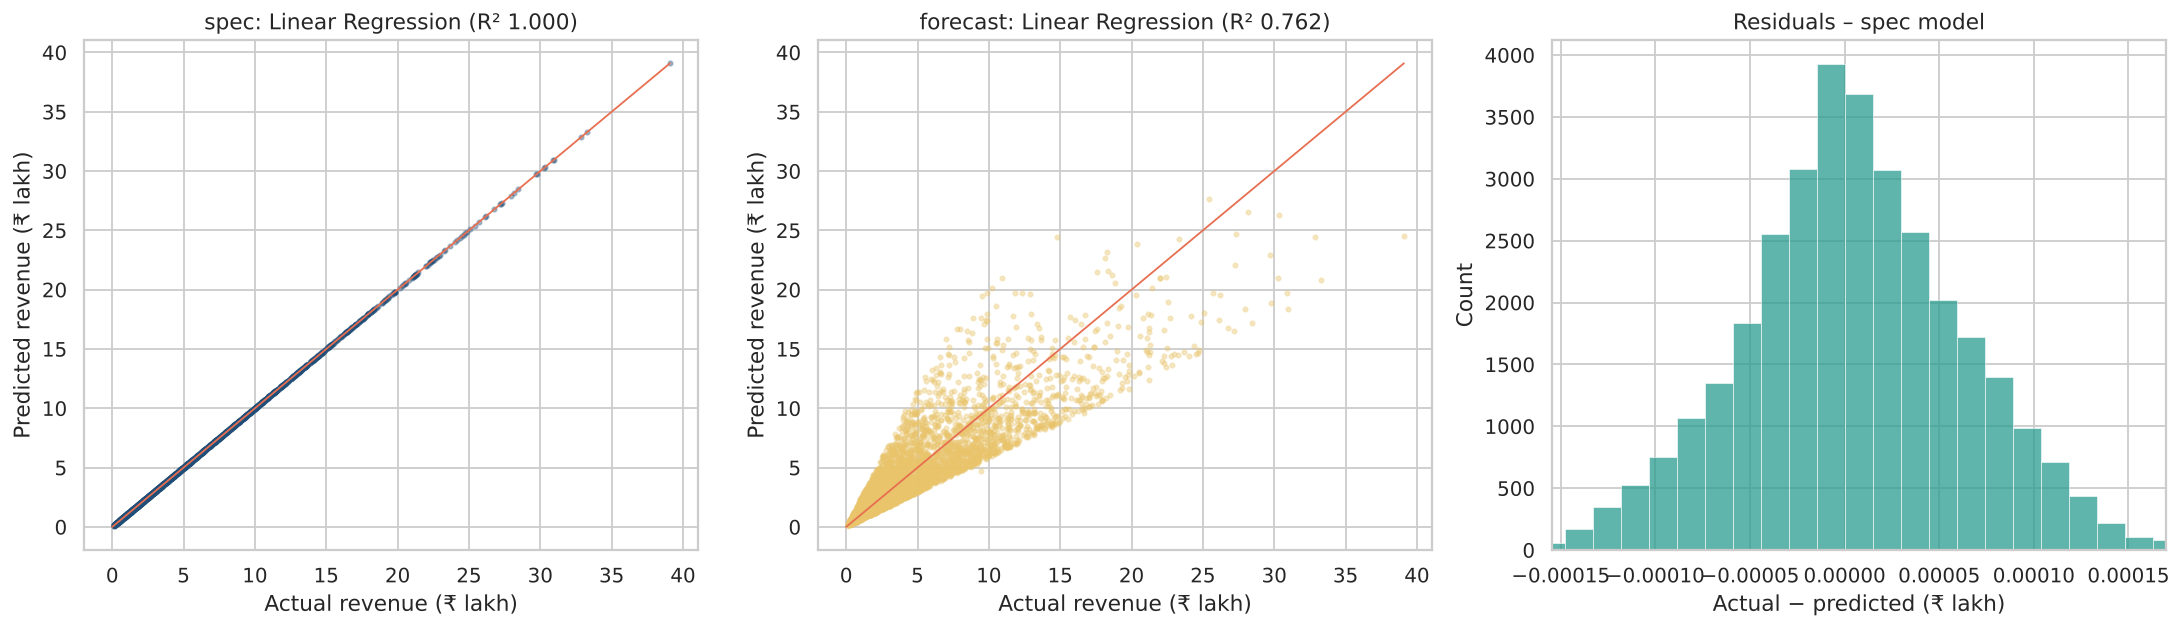

In [37]:
display(Image(config.FIGURES_DIR / '11_regression_actual_vs_predicted.png'))

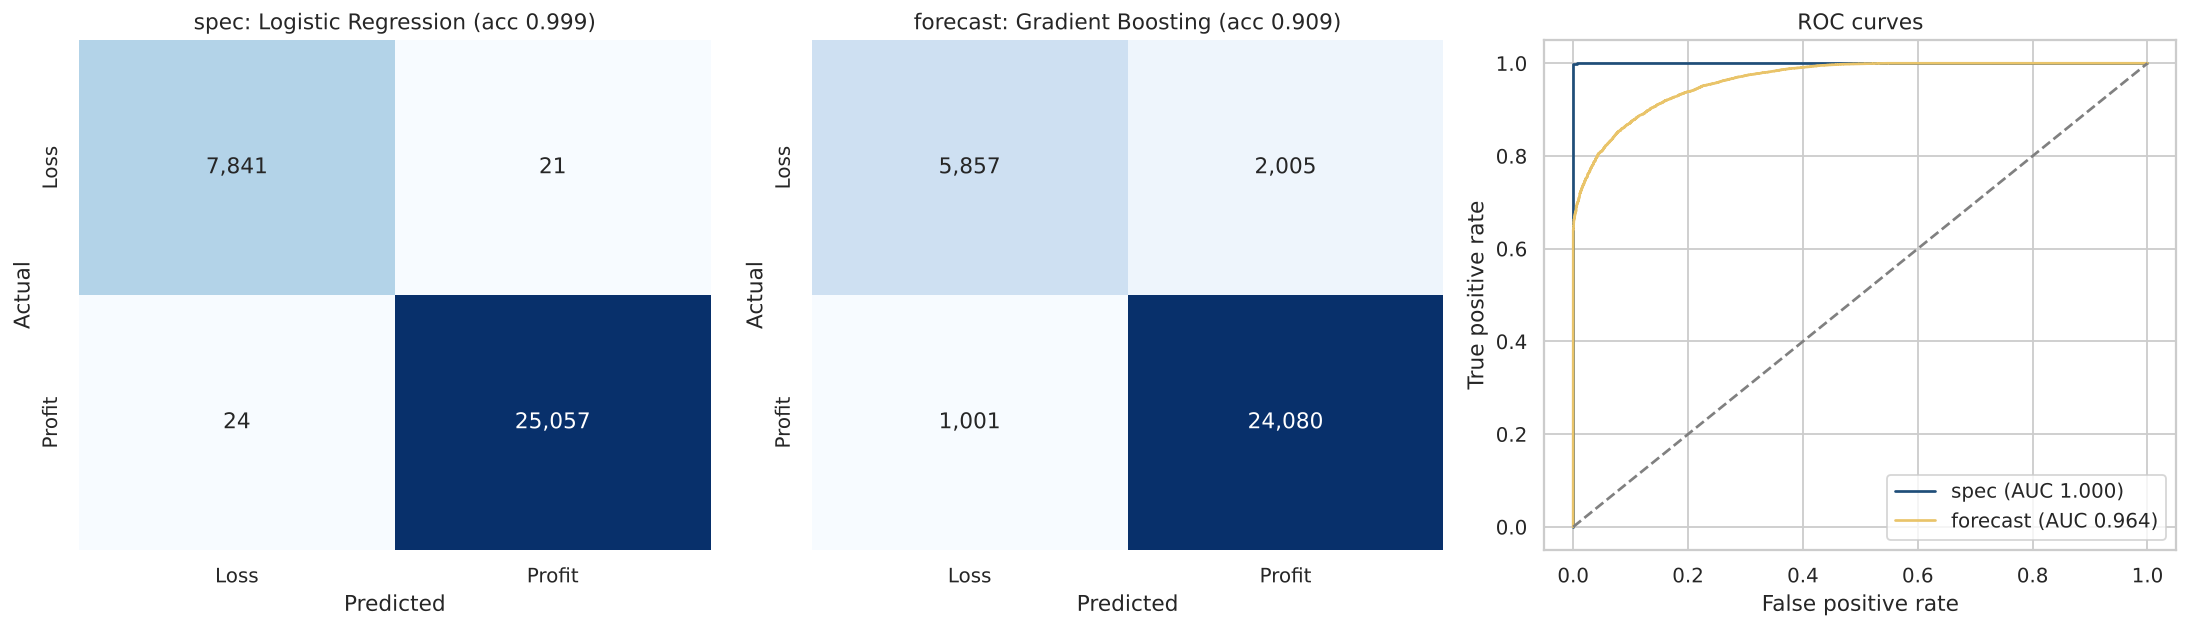

In [38]:
display(Image(config.FIGURES_DIR / '12_classification_confusion_roc.png'))

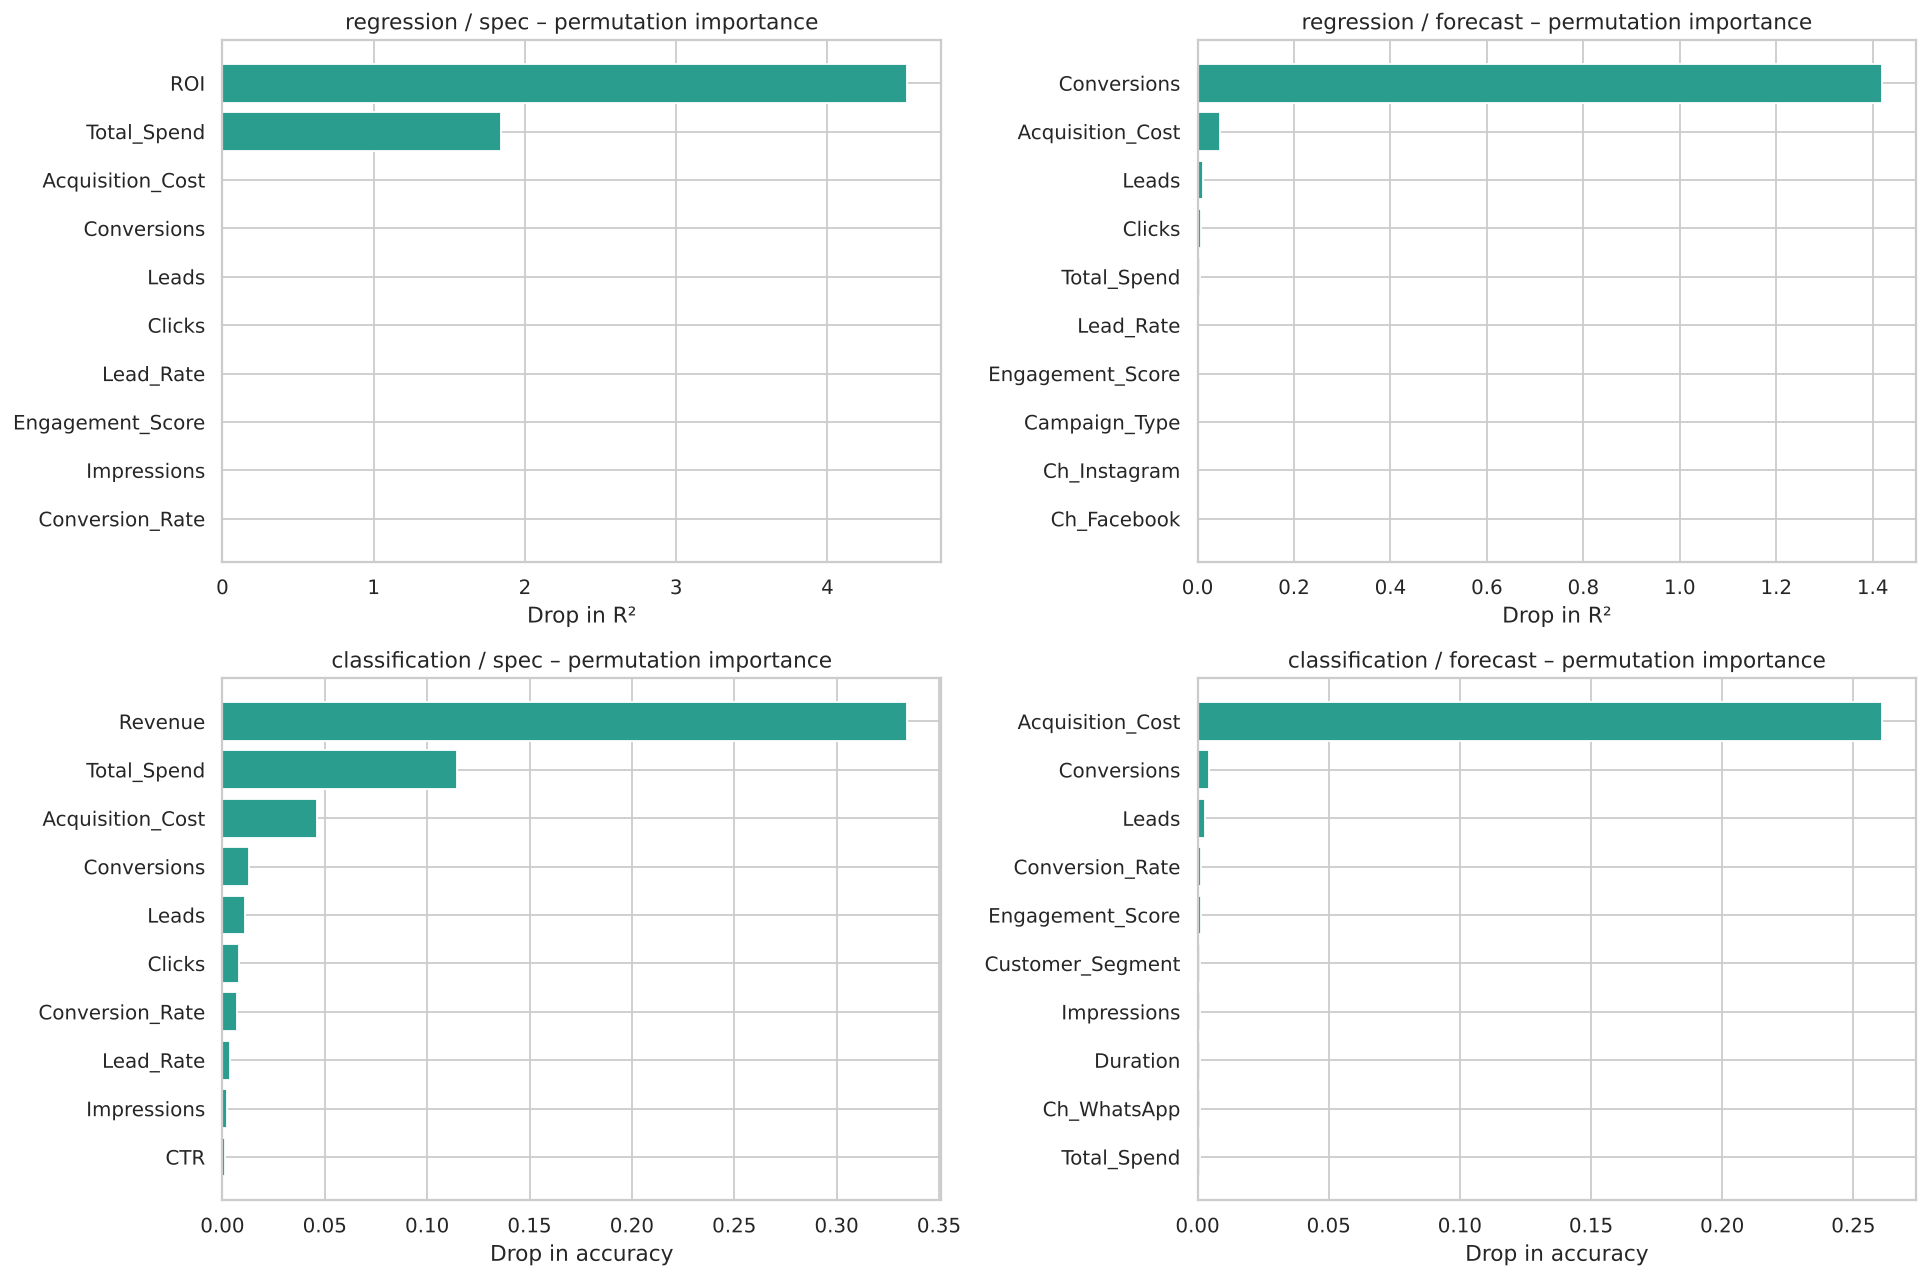

In [39]:
display(Image(config.FIGURES_DIR / '13_feature_importance.png'))

### Why the spec models are near-perfect, and how far the forecast models can go
* `Revenue = Spend × (1 + ROI)` exactly, so with ROI available a linear model on log-features reproduces revenue (R² = 1.0).
* `Profit ⇔ Revenue > Spend`, so with Revenue available (and ROI excluded) the classifier is ~99.9% accurate.
* Without ROI or Revenue, the missing piece is order value per conversion, which is spread evenly over ₹200–800 and recorded nowhere else. The cells below compute the best accuracy and R² any model could reach under that condition.

In [40]:
c = feat.Acquisition_Cost; p = ((800 - c) / 600).clip(0, 1)
print(f'Theoretical best accuracy without Revenue/ROI: {np.maximum(p, 1 - p).mean():.4f}')
print(f"Forecast classifier accuracy:                 {res['classification_forecast']['test_metrics']['Accuracy']:.4f}")
r2_ceiling = 1 - ((feat.Revenue - 500 * feat.Conversions) ** 2).sum() / ((feat.Revenue - feat.Revenue.mean()) ** 2).sum()
print(f'Revenue R² if order value were always its ₹500 mean: {r2_ceiling:.4f}')
print(f"Forecast regression R²:                            {res['regression_forecast']['test_metrics']['R2']:.4f}")

Theoretical best accuracy without Revenue/ROI: 0.9108
Forecast classifier accuracy:                 0.9088
Revenue R² if order value were always its ₹500 mean: 0.7722
Forecast regression R²:                            0.7621


## 7. Prediction on a new campaign (same preprocessing as training)

In [41]:
demo = dict(Brand='Nykaa', Campaign_Type='Paid Ads', Target_Audience='Youth', Language='Hindi',
            Customer_Segment='Youth', Channel_Used=['Instagram', 'YouTube'], Duration=15,
            Impressions=60000, Clicks=5000, Leads=2000, Conversions=1100, Acquisition_Cost=150,
            Engagement_Score=13.5, Date='2025-03-10', ROI=2.3, Revenue=None)
rows = []
for cost in [150, 450, 1200]:
    for v in ['spec', 'forecast']:
        d = dict(demo, Acquisition_Cost=cost, ROI=(500 - cost) / cost)
        r = predict_campaign(d, v)
        rows.append({'acq_cost': cost, 'model_set': v, 'pred_revenue': round(r['predicted_revenue']),
                     'spend': r['total_spend'], 'prediction': r['prediction'],
                     'p_profit': round(r['profit_probability'], 3)})
pd.DataFrame(rows)

,acq_cost,model_set,pred_revenue,spend,prediction,p_profit
0,150,spec,549999,165000.0,Profit,1.000
1,150,forecast,516120,165000.0,Profit,1.000
2,450,spec,550003,495000.0,Profit,1.000
3,450,forecast,516675,495000.0,Profit,0.594
4,1200,spec,550009,1320000.0,Loss,0.000
5,1200,forecast,517057,1320000.0,Loss,0.000


## 8. Summary
* 166,665 raw campaigns → **164,712** after cleaning. ROI was validated, 28,000 values were recovered exactly from the ROI identity, and the remaining gaps were imputed.
* **Acquisition cost per conversion decides profitability.** Channel mix, campaign type, audience and brand hardly matter.
* Spec models: revenue **R² 1.000**, profit/loss **accuracy 99.9%**, both above the brief's 0.95 targets, with ROI kept out of the classifier.
* Forecast models (no ROI/Revenue): R² 0.76 and accuracy 90.9%, close to the theoretical ceiling.
* See `reports/EDA_Report.md` and `reports/Model_Evaluation_Report.md` for the full write-up.